<a href="https://colab.research.google.com/github/maryslopes/AI-Data-Handling/blob/M2-project/M2_equipment_failure_notebook_Statistical_Reasoning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Statistical Reasoning and Pandas for EDA



## Learning outcomes

You will inspect semantic variable roles, calculate resistant summaries, diagnose missingness, compare groups using effect sizes, construct a bootstrap interval, examine conditional patterns and document dependence, distribution-shift and leakage risks.

## 1 Colab setup

Use Runtime then Run all after completing the TODO cells. Colab already contains Python; the following command ensures that the scientific packages are available.

In [2]:
%pip install -q pandas numpy scipy matplotlib seaborn statsmodels

In [3]:
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.13.16
pandas: 2.2.3
NumPy: 2.1.3


A fixed seed makes resampling repeatable. Recording package versions helps another analyst reproduce the computational environment.

## 2 Load and validate the data

The public URL is a common fallback. Students who loaded the file into GCS during Sprint 1 may replace the URL-loading cell with their authenticated GCS code while retaining the dataframe name df.

# Setup Authentication

In [4]:
from google.colab import auth
auth.authenticate_user()

# Access GCS Bucket

In [5]:
import gcsfs
import pandas as pd

# Replace with your bucket and file path
fs = gcsfs.GCSFileSystem(project='equipment-failure-20122724')
with fs.open('gs://equipment-failure-20122724/raw/Equipment-Failure.csv') as f:
      df = pd.read_csv(f)

# Validation Check

In [6]:
# Core operational columns
required_core = {
    "UDI", "Product ID", "Type",
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]",
    "Tool wear [min]", "Machine failure"
}

# Failure subtype flags
required_failures = {"TWF", "HDF", "PWF", "OSF", "RNF"}

# Validate presence
assert required_core.issubset(df.columns), "Missing core columns!"
assert required_failures.issubset(df.columns), "Missing failure subtype columns!"

# Additional integrity checks
assert df["UDI"].is_unique, "UDI must be unique"
assert set(df["Machine failure"].unique()).issubset({0, 1}), "Failure flag must be 0/1"
print("Initial data-contract checks passed.")

Initial data-contract checks passed.


## 3 Schema and semantic-role audit

Pandas dtypes describe storage. Analytical roles describe meaning.

In [7]:
schema_audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "unique": df.nunique(dropna=True),
    "role": [
        "Identifier",          # UDI
        "Categorical (ID)",    # Product ID
        "Categorical (Type)",  # Type
        "Numeric Feature",     # Air temperature [K]
        "Numeric Feature",     # Process temperature [K]
        "Numeric Feature",     # Rotational speed [rpm]
        "Numeric Feature",     # Torque [Nm]
        "Numeric Feature",     # Tool wear [min]
        "Target (Binary)",     # Machine failure
        "Target subtype",      # TWF
        "Target subtype",      # HDF
        "Target subtype",      # PWF
        "Target subtype",      # OSF
        "Target subtype",      # RNF
        "Partition/Metadata"   # split
    ]
}, index=df.columns)

display(schema_audit)


,dtype,non_null,missing,unique,role
UDI,int64,10000,0,10000,Identifier
Product ID,object,10000,0,10000,Categorical (ID)
Type,object,10000,0,3,Categorical (Type)
Air temperature [K],float64,10000,0,93,Numeric Feature
Process temperature [K],float64,10000,0,82,Numeric Feature
Rotational speed [rpm],int64,10000,0,941,Numeric Feature
Torque [Nm],float64,10000,0,577,Numeric Feature
Tool wear [min],int64,10000,0,246,Numeric Feature
Machine failure,int64,10000,0,2,Target (Binary)
TWF,int64,10000,0,2,Target subtype


# Feature role mapping

In [8]:
feature_roles = pd.DataFrame({
    "Column": [
        "UDI", "Product ID", "Type",
        "Air temperature [K]", "Process temperature [K]",
        "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]",
        "Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"
    ],
    "Role": [
        "Identifier",              # Unique ID, not used as feature
        "Categorical (ID)",        # Product grouping
        "Categorical (Type)",      # Equipment type
        "Numeric Feature",         # Sensor reading
        "Numeric Feature",         # Sensor reading
        "Numeric Feature",         # Sensor reading
        "Numeric Feature",         # Sensor reading
        "Numeric Feature",         # Sensor reading
        "Target (Binary)",         # Main failure flag
        "Target subtype",          # Tool wear failure
        "Target subtype",          # Heat dissipation failure
        "Target subtype",          # Power failure
        "Target subtype",          # Overstrain failure
        "Target subtype"           # Random failure
    ],
    "Notes": [
        "Do not use in training",
        "May be useful for grouping",
        "Categorical encoding needed",
        "Continuous variable",
        "Continuous variable",
        "Continuous variable",
        "Continuous variable",
        "Continuous variable",
        "Binary classification target",
        "Subtype label (multi-label)",
        "Subtype label (multi-label)",
        "Subtype label (multi-label)",
        "Subtype label (multi-label)",
        "Subtype label (multi-label)"
    ]
})

display(feature_roles)

,Column,Role,Notes
0,UDI,Identifier,Do not use in training
1,Product ID,Categorical (ID),May be useful for grouping
2,Type,Categorical (Type),Categorical encoding needed
3,Air temperature [K],Numeric Feature,Continuous variable
4,Process temperature [K],Numeric Feature,Continuous variable
5,Rotational speed [rpm],Numeric Feature,Continuous variable
6,Torque [Nm],Numeric Feature,Continuous variable
7,Tool wear [min],Numeric Feature,Continuous variable
8,Machine failure,Target (Binary),Binary classification target
9,TWF,Target subtype,Subtype label (multi-label)


## 4 Numerical summaries
Mean and standard deviation are sensitive to extremes. Median and IQR are more resistant. Calculate both pairs before deciding which best communicates the distribution.

In [9]:
def profile(series):
    observed = series.dropna()
    q1, q3 = observed.quantile([0.25, 0.75])
    return pd.Series({
        "n": observed.size,
        "missing": series.isna().sum(),
        "mean": observed.mean(),
        "median": observed.median(),
        "std": observed.std(),
        "IQR": q3 - q1,
        "min": observed.min(),
        "max": observed.max(),
        "skew": observed.skew()
    })

numeric_features = [
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"
]

summary = df[numeric_features].apply(profile).T
display(summary)

,n,missing,mean,median,std,IQR,min,max,skew
Air temperature [K],"10,000.000",0.000,300.005,300.100,2.000,3.200,295.300,304.500,0.114
Process temperature [K],"10,000.000",0.000,310.006,310.100,1.484,2.300,305.700,313.800,0.015
Rotational speed [rpm],"10,000.000",0.000,"1,538.776","1,503.000",179.284,189.000,"1,168.000","2,886.000",1.993
Torque [Nm],"10,000.000",0.000,39.987,40.100,9.969,13.600,3.800,76.600,-0.010
Tool wear [min],"10,000.000",0.000,107.951,108.000,63.654,109.000,0.000,253.000,0.027


## 5 Distribution plots and transformation

A histogram exposes shape; a boxplot shows quartiles and flagged extremes. A flagged value is not automatically erroneous.

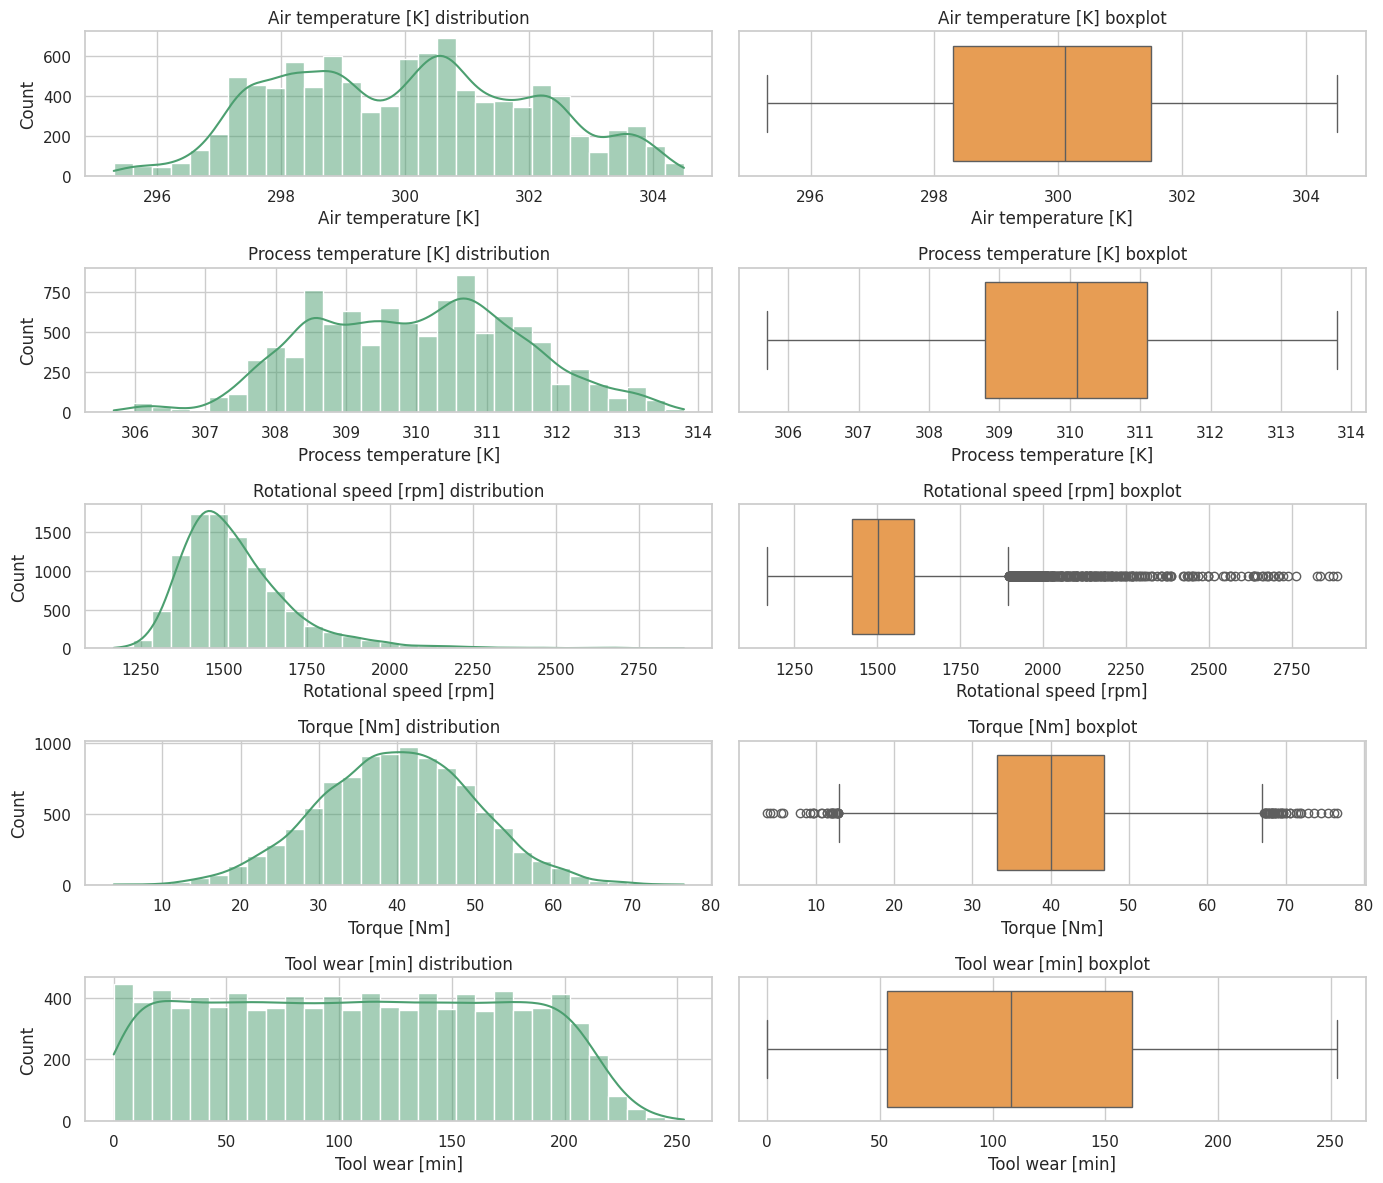

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ["Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

fig, axes = plt.subplots(len(features), 2, figsize=(14, 12))

for i, col in enumerate(features):
    sns.histplot(data=df, x=col, bins=30, kde=True, ax=axes[i, 0], color="#4C9F70")
    sns.boxplot(data=df, x=col, ax=axes[i, 1], color="#FF9D3B")
    axes[i, 0].set_title(f"{col} distribution")
    axes[i, 1].set_title(f"{col} boxplot")

plt.tight_layout()
plt.show()

# Correlation heatmap

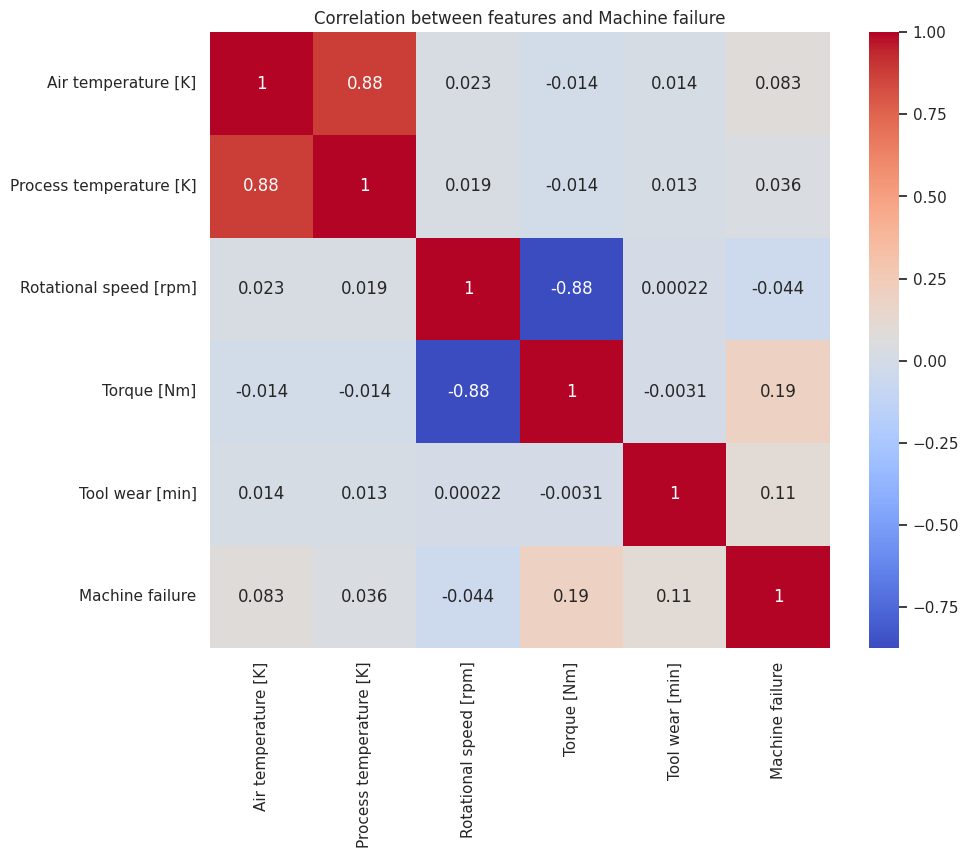

In [11]:
plt.figure(figsize=(10,8))
sns.heatmap(df[features + ["Machine failure"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation between features and Machine failure")
plt.show()

## 6 Categorical summaries and majority baseline

Counts show evidential support. Proportions enable comparison. The largest target-class proportion is a basic accuracy baseline.

In [12]:
# Main target: Machine failure
target = df["Machine failure"].value_counts(dropna=False).to_frame("count")
target["proportion"] = target["count"] / len(df)
display(target)

print(f"Majority-class accuracy baseline: {target['proportion'].max():.1%}")

# Subtypes: TWF, HDF, PWF, OSF, RNF
for subtype in ["TWF", "HDF", "PWF", "OSF", "RNF"]:
    subtype_counts = df[subtype].value_counts(dropna=False).to_frame("count")
    subtype_counts["proportion"] = subtype_counts["count"] / len(df)
    print(f"\n{subtype} distribution:")
    display(subtype_counts)

,count,proportion
Machine failure,,
0,9661,0.966
1,339,0.034


Majority-class accuracy baseline: 96.6%

TWF distribution:


,count,proportion
TWF,,
0,9954,0.995
1,46,0.005



HDF distribution:


,count,proportion
HDF,,
0,9885,0.989
1,115,0.011


...

,count,proportion
PWF,,
0,9905,0.991
1,95,0.009



OSF distribution:


,count,proportion
OSF,,
0,9902,0.990
1,98,0.010



RNF distribution:


,count,proportion
RNF,,
0,9981,0.998
1,19,0.002


## 7 Missingness extent and structure

A missing percentage measures extent. Grouped missingness rates provide evidence about structure, but cannot prove MCAR, MAR or MNAR.

In [13]:
import matplotlib.pyplot as plt

# Calculate missingness percentage for all columns
missing = df.isna().mean().mul(100).sort_values(ascending=False).rename("missing_percent")
display(missing.to_frame())

# Plot missingness extent only if there are missing values
if (missing > 0).any():
    ax = missing[missing > 0].sort_values().plot(kind="barh", color="#E64141", figsize=(8, 4))
    ax.set_xlabel("Missing values (%)")
    ax.set_title("Missingness extent in equipment failure dataset")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected in the dataset.")

,missing_percent
UDI,0.000
Product ID,0.000
Type,0.000
Air temperature [K],0.000
Process temperature [K],0.000
Rotational speed [rpm],0.000
Torque [Nm],0.000
Tool wear [min],0.000
Machine failure,0.000
TWF,0.000


No missing values detected in the dataset.


## 8 Group comparison and effect size

Report counts and within-group rates before calculating the percentage-point risk difference. Treat the result as an observed association, not an isolated causal effect.

In [14]:
# Group comparison: failure rate by machine type
failure_by_type = (
    df.groupby("Type", observed=True)
      .agg(
          machines=("UDI", "size"),
          failures=("Machine failure", "sum"),
          failure_rate=("Machine failure", "mean")
      )
)
failure_by_type["failure_percent"] = 100 * failure_by_type["failure_rate"]
display(failure_by_type)

# Example: risk difference between two types (say L vs M)
if "L" in failure_by_type.index and "M" in failure_by_type.index:
    difference = failure_by_type.loc["L", "failure_rate"] - failure_by_type.loc["M", "failure_rate"]
    print(f"Observed risk difference (L vs M): {100*difference:.1f} percentage points")

,machines,failures,failure_rate,failure_percent
Type,,,,
H,1003,21,0.021,2.094
L,6000,235,0.039,3.917
M,2997,83,0.028,2.769


Observed risk difference (L vs M): 1.1 percentage points


## 9 Chi-square and Cramer's V

The contingency table is the evidence. Chi-square evaluates compatibility with independence; Cramer's V summarises association magnitude. Neither establishes causality.

In [15]:
import pandas as pd
import numpy as np
from scipy import stats

# Example: contingency table of Machine type vs Machine failure
table = pd.crosstab(df["Type"], df["Machine failure"])
display(table)

# Chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(table)

# Cramer's V
n = table.to_numpy().sum()
rows, cols = table.shape
cramers_v = np.sqrt((chi2 / n) / min(cols - 1, rows - 1))

print(f"Chi-square: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.3e}")
print(f"Cramer's V: {cramers_v:.3f}")

# Expected counts under independence
display(pd.DataFrame(expected, index=table.index, columns=table.columns))

Machine failure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83


Chi-square: 13.752
Degrees of freedom: 2
p-value: 1.032e-03
Cramer's V: 0.037


Machine failure,0,1
Type,,
H,968.998,34.002
L,"5,796.600",203.400
M,"2,895.402",101.598


Interpret the expected counts, p-value and Cramer's V. Explain why sample size affects the p-value and why the result is not causal.

## 10 Bootstrap uncertainty

Bootstrap the female-minus-male survival-rate difference. If observations were clustered by household, the household rather than the row might need to be resampled.

In [16]:
def failure_difference(data, type1="L", type2="M"):
    rates = data.groupby("Type")["Machine failure"].mean()
    return rates.get(type1, 0) - rates.get(type2, 0)

# Observed difference
observed = failure_difference(df)

# Bootstrap resampling
boot = []
for _ in range(2000):
    sample = df.sample(len(df), replace=True)
    boot.append(failure_difference(sample))

boot = np.asarray(boot)

# Confidence interval
lower, upper = np.percentile(boot, [2.5, 97.5])

print(f"Observed difference (L vs M): {observed:.3f}")
print(f"95% percentile bootstrap interval: [{lower:.3f}, {upper:.3f}]")

Observed difference (L vs M): 0.011
95% percentile bootstrap interval: [0.004, 0.019]


## 11 Conditional analysis

Compare marginal survival rates with class-conditional rates. Retain counts so that unstable small groups remain visible.

,Type,TWF,machines,failure_rate,failure_percent
0,H,0,996,0.014,1.406
1,H,1,7,1.000,100.000
2,L,0,5975,0.035,3.515
3,L,1,25,1.000,100.000
4,M,0,2983,0.023,2.313
5,M,1,14,1.000,100.000


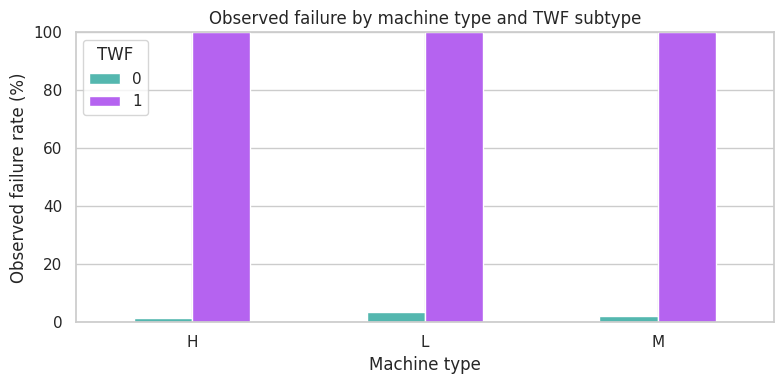

In [17]:
# Conditional analysis: failure rate by machine type and subtype
conditional = (
    df.groupby(["Type", "TWF"], observed=True)
      .agg(machines=("UDI", "size"),
           failure_rate=("Machine failure", "mean"))
      .assign(failure_percent=lambda x: 100 * x["failure_rate"])
      .reset_index()
)
display(conditional)

# Pivot for visualization (example: Type vs TWF flag)
conditional.pivot(index="Type", columns="TWF", values="failure_percent").plot(
    kind="bar", figsize=(8, 4), color=["#54B7AF", "#B563F0"]
)
plt.ylabel("Observed failure rate (%)")
plt.xlabel("Machine type")
plt.title("Observed failure by machine type and TWF subtype")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 12 Dependence shift and leakage

Create a risk table for your project. Consider related entities, time order, source changes, feature-availability time and preprocessing fitted before splitting.

In [18]:
project_risks = pd.DataFrame({
    "risk": [
        "Data leakage from post-failure measurements",
        "Dependence shift across machine types",
        "Temporal leakage (using future sensor readings)",
        "Imbalanced failure subtype distribution",
        "Feature availability mismatch at prediction time"
    ],
    "evidence_to_check": [
        "Confirm timestamps of tool wear and torque are before failure event",
        "Compare failure rates across Type H, L, M over time",
        "Ensure training only uses data available before failure",
        "Check subtype counts and proportions",
        "Verify features used in training are available in real-time monitoring"
    ],
    "planned_response": [
        "Drop or adjust features recorded after failure",
        "Stratify or adjust models per machine type",
        "Use proper train/test split by time order",
        "Apply resampling or class weights",
        "Restrict model inputs to real-time accessible features"
    ]
})

display(project_risks)

,risk,evidence_to_check,planned_response
0,Data leakage from post-failure measurements,Confirm timestamps of tool wear and torque are...,Drop or adjust features recorded after failure
1,Dependence shift across machine types,"Compare failure rates across Type H, L, M over...",Stratify or adjust models per machine type
2,Temporal leakage (using future sensor readings),Ensure training only uses data available befor...,Use proper train/test split by time order
3,Imbalanced failure subtype distribution,Check subtype counts and proportions,Apply resampling or class weights
4,Feature availability mismatch at prediction time,Verify features used in training are available...,Restrict model inputs to real-time accessible ...
